# Standardized Housing Cost Index - Data Analysis

This notebook is made to analyze the dataset for the housing cost affordability. This value is comparing the median net monthly income divided by the average price for a 93.7 m2 apartment in a given province. 

## Part 1 - Data Preparations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

from scipy import stats

In [2]:
df = pd.read_csv("panel_data.csv", encoding= "utf-8")
df['Year'] = df['Year'].astype(int)
df = df.rename(columns={"Affordability Index": "Rent Burden", "Ln affordability Index": "Ln Rent Burden"})

In [3]:
print(df.isnull().sum())

Province                        0
Year                            0
Rent Burden                     0
Ln Rent Burden                  0
Region                          0
Median net stipend              0
Average rent                    0
Mortgage rate                   0
North                           0
Centre                          0
South                           0
Islands                         0
City                            0
Regional remote work rate       0
Population density              0
Short-term rental per capita    0
Total Migration per 1k          0
Population                      0
Unemployment rate               0
dtype: int64


## Part 2 - Exploratory Data Analysis

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,642.0,2020.500000,1.709157,2018.000000,2019.000000,2020.500000,2022.00000,2.023000e+03
Rent Burden,642.0,0.436059,0.146849,0.230000,0.350000,0.410000,0.49000,1.300000e+00
Ln Rent Burden,642.0,-0.874817,0.287944,-1.469676,-1.049822,-0.891598,-0.71335,2.623643e-01
Median net stipend,642.0,1542.550794,103.673697,1279.830000,1467.077500,1538.190000,1609.91000,1.879370e+03
Average rent,642.0,676.646417,247.382682,328.000000,520.000000,632.000000,760.00000,2.160000e+03
Mortgage rate,642.0,0.068950,0.007582,0.062900,0.063600,0.066250,0.06950,8.520000e-02
North,642.0,0.439252,0.496683,0.000000,0.000000,0.000000,1.00000,1.000000e+00
Centre,642.0,0.205607,0.404460,0.000000,0.000000,0.000000,0.00000,1.000000e+00
South,642.0,0.224299,0.417445,0.000000,0.000000,0.000000,0.00000,1.000000e+00
Islands,642.0,0.130841,0.337489,0.000000,0.000000,0.000000,0.00000,1.000000e+00


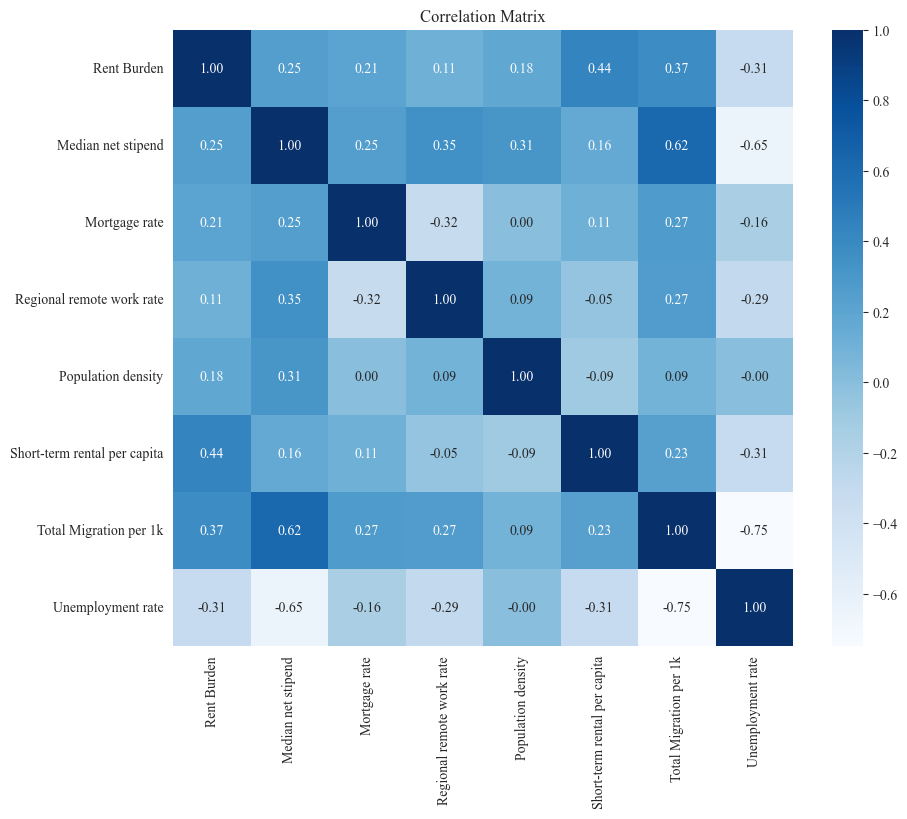

In [5]:
df_corr = df.select_dtypes(include=["float"])
df_corr = df_corr.drop(columns=["Ln Rent Burden"])
df_corr = df_corr.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [6]:
year_list = df['Year'].unique()
area_list = ['North', 'Centre', 'South', 'Islands']
area_pop_dict = {}

for year in year_list:
    for area in area_list:
        area_pop = df[(df['Year'] == year) & (df[area] == 1)]['Population'].sum()
        area_pop_dict[(year, area)] = area_pop

df['Area population'] = df.apply(lambda row: area_pop_dict[(row['Year'], [a for a in area_list if row[a] == 1][0])], axis=1)
df['Area population'] = df['Area population'].astype(int)

#Create an area remote work rate by sumiing the population based on the area and year for all provinces and then dividing by the total population of the area to get a weighted average remote work rate for the area.
area_wfh_dict = {}
for year in year_list:
    for wfh in area_list:
        area_wfh = (df[(df['Year'] == year) & (df[wfh] == 1)]['Regional remote work rate']
                    *df['Population']).sum()
        area_wfh = area_wfh/area_pop_dict[(year, wfh)]
        area_wfh_dict[(year, wfh)] = area_wfh

df['Weighted average WFH'] = df.apply(lambda row: area_wfh_dict[(row['Year'], [a for a in area_list if row[a] == 1][0])], axis=1)
df['Weighted average WFH'] = (df['Weighted average WFH']).round(4)

rent_burden_dict = {}
for year in year_list:
    for afford in area_list:
        area_wfh = (df[(df['Year'] == year) & (df[afford] == 1)]['Rent Burden']
                    *df['Population']).sum()
        area_wfh = area_wfh/area_pop_dict[(year, afford)]
        area_wfh_dict[(year, afford)] = area_wfh

df['Weighted average Rent Burden'] = df.apply(lambda row: area_wfh_dict[(row['Year'], [a for a in area_list if row[a] == 1][0])], axis=1)
df['Weighted average Rent Burden'] = (df['Weighted average Rent Burden']).round(4)

Text(0.5, 0, '')

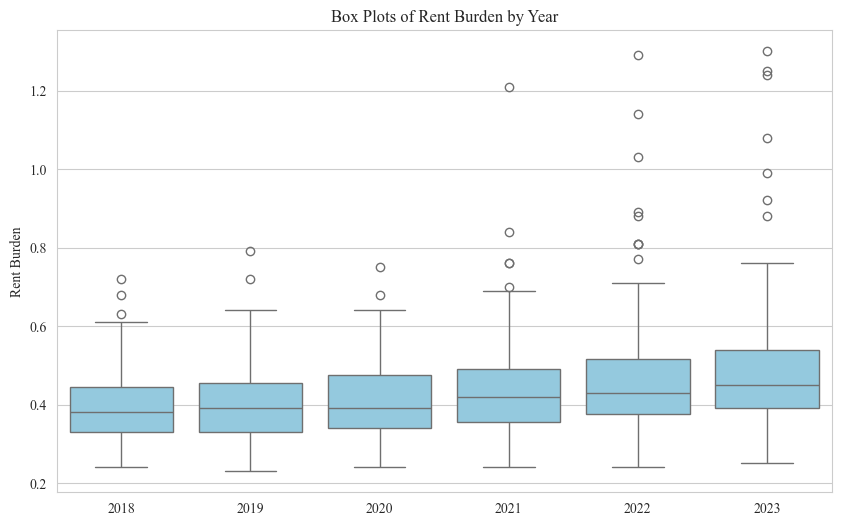

In [7]:
from matplotlib.ticker import MaxNLocator
sns.boxplot(data=df,x = "Year",y = "Rent Burden", color ='skyblue')
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.title("Box Plots of Rent Burden by Year")
plt.ylabel("Rent Burden")
plt.xlabel(None)

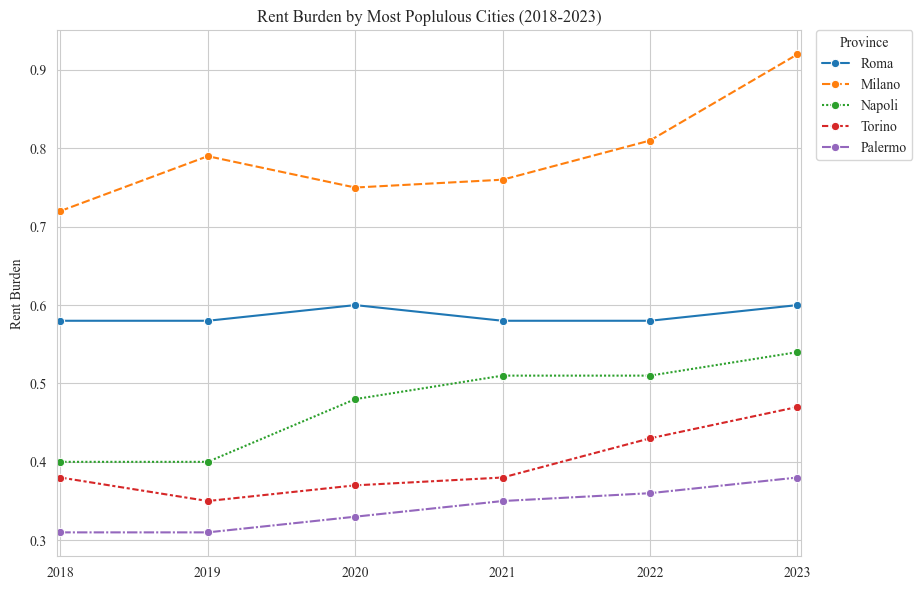

In [8]:
from matplotlib.ticker import MaxNLocator
city_list = ["Roma", "Milano", "Napoli", "Torino", "Palermo"]
df_city = df[df['Province'].isin(city_list)].copy()

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=df_city,
    x="Year",
    y="Rent Burden",
    hue="Province",
    hue_order=city_list,
    style="Province",
    style_order= city_list,
    marker="o",
    errorbar=None,
    ax=ax
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Rent Burden by Most Poplulous Cities (2018-2023)")
ax.legend(title='Province', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, frameon=True)
plt.xlabel(None)
plt.xlim(2017.975, 2023.025)
fig.tight_layout(rect=[0, 0, 0.78, 1])

(2017.975, 2023.025)

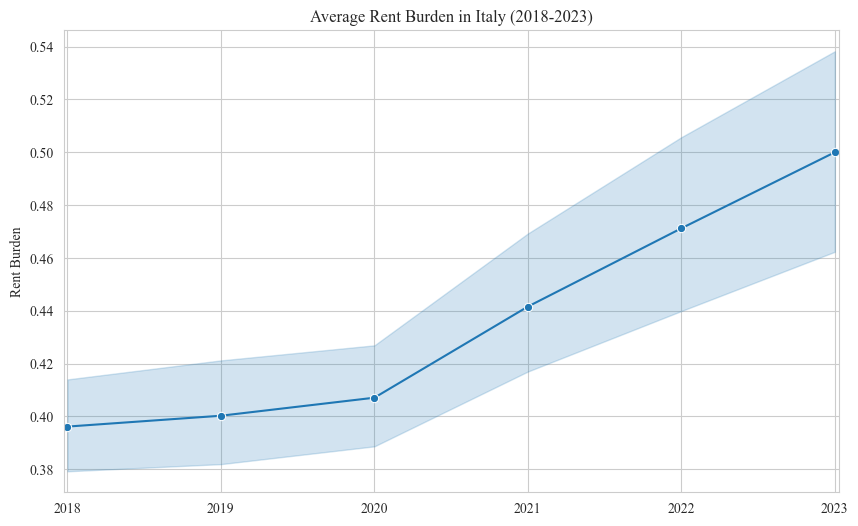

In [9]:
sns.lineplot(data=df, x="Year", y="Rent Burden", marker="o", errorbar="ci")
plt.title("Average Rent Burden in Italy (2018-2023)")
plt.ylabel("Rent Burden")
plt.xlabel(None)
plt.xlim(2017.975, 2023.025)

(2017.975, 2023.025)

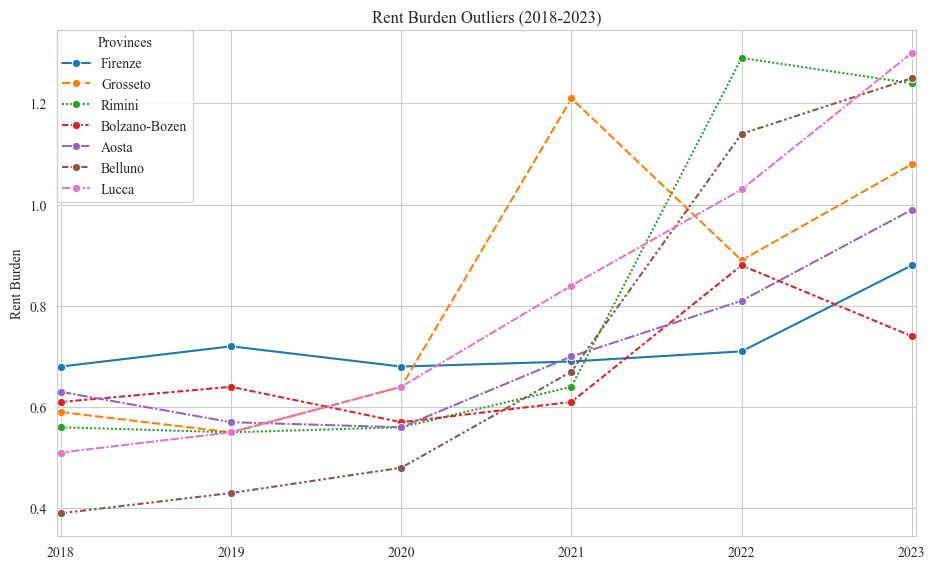

In [10]:
from matplotlib.ticker import MaxNLocator
outlier_list = ["Firenze", "Grosseto", "Rimini", "Bolzano-Bozen", "Aosta", "Belluno", "Lucca"]
df_outlier = df[df['Province'].isin(outlier_list)].copy()

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=df_outlier,
    x="Year",
    y="Rent Burden",
    style="Province",
    style_order=outlier_list,
    hue="Province",
    hue_order=outlier_list,
    marker="o",
    errorbar=None,
    ax=ax
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Rent Burden Outliers (2018-2023)")
ax.legend(title='Provinces', loc='upper left', borderaxespad=0, frameon=True)
fig.tight_layout(rect=[0, 0, 0.78, 1])
plt.xlabel(None)
plt.ylabel("Rent Burden")
plt.xlim(2017.975, 2023.025)

(2017.975, 2023.025)

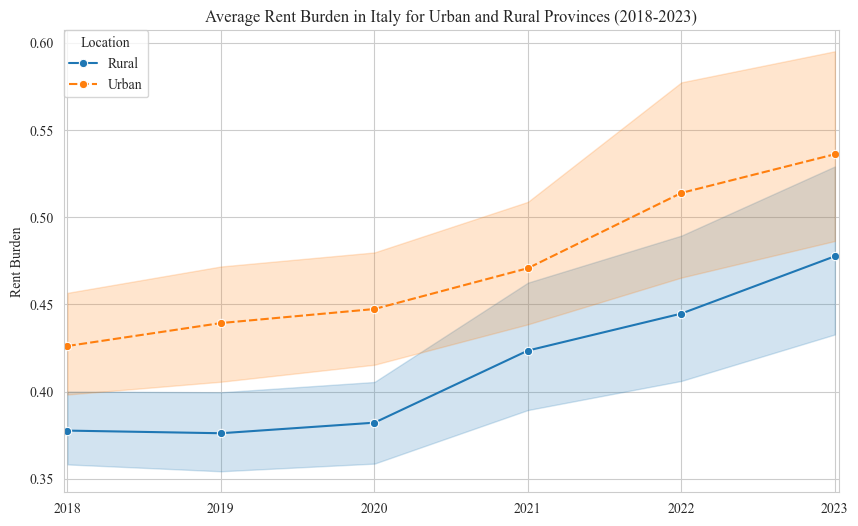

In [11]:
sns.lineplot(data=df, x="Year", y="Rent Burden", hue="City", style="City", marker="o", errorbar="ci", palette={0: "C0", 1: "C1"})
handles, labels = plt.gca().get_legend_handles_labels()
labels = ["Rural" if label == "0" else "Urban" for label in labels]
plt.legend(handles, labels, title='Location', loc='upper left', borderaxespad=0, frameon=True)
plt.ylabel("Rent Burden")
plt.xlabel(None)
plt.title("Average Rent Burden in Italy for Urban and Rural Provinces (2018-2023)")
plt.xlim(2017.975, 2023.025)

## Part 3 - Linear Regression

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import statsmodels.api as sm

In [13]:
# Baseline Linear Regression using statsmodels for detailed statistics
def linear_regression(X, y):
    # Ensure X has only numeric columns
    X = X.select_dtypes(include=[np.number])
    X_with_const = sm.add_constant(X)
    baseline = sm.OLS(y, X_with_const).fit()
    title = y.name if hasattr(y, 'name') else "Dependent Variable"
    title = title.upper()

    # Predictions
    y_pred = baseline.predict(X_with_const)

    # Evaluate
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae = mean_absolute_error(y, y_pred)
    r2 = r2_score(y, y_pred)
    header = f"{'Variable':^45}| {'Coef':^9} | {'StdErr':^9} | {'p-value':^8} | {'95% CI':^24}"

    #print("=" * len(header))
    print(f"LINEAR REGRESSION RESULTS FOR {title}")
    #print("=" * len(header))
    print(f"\nANOVA Test:")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  MAE:  {mae:.4f}")
    print(f"  R²:   {r2:.4f}")
    print(f"  F-statistic: {baseline.fvalue:.4f}")
    print(f"  Model p-value: {baseline.f_pvalue:.4f}")
    #print("=" * len(header))

    # Print details for each independent variable
    print("\nCoefficients, Standard Errors, p-values, and 95% CI for each variable:")
    print(header)
    print('-' * len(header))
    for var in X_with_const.columns:
        if var == 'const':
            continue
        coeff = baseline.params[var]
        std_err = baseline.bse[var]
        p_val = baseline.pvalues[var]
        ci_low, ci_high = baseline.conf_int().loc[var]
        ci_str = f"[{ci_low:.4f}, {ci_high:.4f}]"
        print(f"{var:^45}| {coeff:>9.4f} | {std_err:>9.4f} | {p_val:>8.4f} | {ci_str:^24}")

In [14]:
y = df["Rent Burden"]
y_log = df["Ln Rent Burden"]
X = df[[
        #'Year',
        'Regional remote work rate',
        #'Province',
        "Total Migration per 1k",
        'Short-term rental per capita',
        'Mortgage rate',
        'Population density',
        'Unemployment rate',
        #'North',
        'Centre',
        'South',
        'Islands',
        "City"
       ]]

LINEAR REGRESSION RESULTS FOR LN RENT BURDEN

ANOVA Test:
  RMSE: 0.2852
  MAE:  0.2157
  R²:   0.0174
  F-statistic: 11.3637
  Model p-value: 0.0008

Coefficients, Standard Errors, p-values, and 95% CI for each variable:
                  Variable                   |   Coef    |  StdErr   | p-value  |          95% CI         
----------------------------------------------------------------------------------------------------------
          Regional remote work rate          |    0.5694 |    0.1689 |   0.0008 |     [0.2377, 0.9010]    


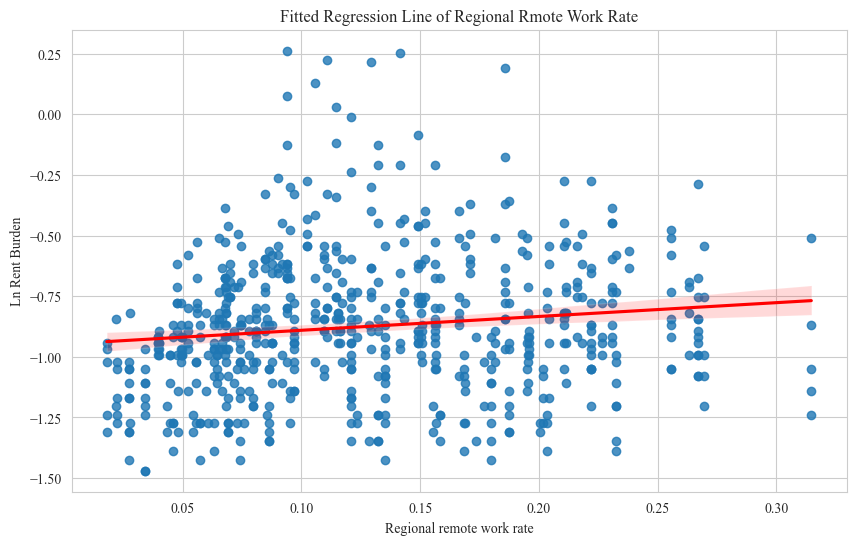

In [15]:
# Use original function interface with DataFrame input for explanatory variables
reg_WFH = linear_regression(df[['Regional remote work rate']], y=y_log)
sns.regplot(data=df, x=df[['Regional remote work rate']], y=y_log, line_kws=dict(color="r"))
plt.title(f"Fitted Regression Line of Regional Rmote Work Rate")
plt.show()

In [16]:
reg_nat_log = linear_regression(X=X, y=y)

LINEAR REGRESSION RESULTS FOR RENT BURDEN

ANOVA Test:
  RMSE: 0.1173
  MAE:  0.0789
  R²:   0.3612
  F-statistic: 35.6768
  Model p-value: 0.0000

Coefficients, Standard Errors, p-values, and 95% CI for each variable:
                  Variable                   |   Coef    |  StdErr   | p-value  |          95% CI         
----------------------------------------------------------------------------------------------------------
          Regional remote work rate          |    0.2475 |    0.0823 |   0.0028 |     [0.0858, 0.4092]    
           Total Migration per 1k            |    0.0089 |    0.0021 |   0.0000 |     [0.0048, 0.0130]    
        Short-term rental per capita         |    0.0467 |    0.0040 |   0.0000 |     [0.0389, 0.0544]    
                Mortgage rate                |    2.3458 |    0.7337 |   0.0015 |     [0.9051, 3.7866]    
             Population density              |    0.0001 |    0.0000 |   0.0000 |     [0.0001, 0.0001]    
              Unemployment rate 

In [17]:
reg_nat_log = linear_regression(X=X, y=y_log)

LINEAR REGRESSION RESULTS FOR LN RENT BURDEN

ANOVA Test:
  RMSE: 0.2185
  MAE:  0.1675
  R²:   0.4235
  F-statistic: 46.3490
  Model p-value: 0.0000

Coefficients, Standard Errors, p-values, and 95% CI for each variable:
                  Variable                   |   Coef    |  StdErr   | p-value  |          95% CI         
----------------------------------------------------------------------------------------------------------
          Regional remote work rate          |    0.4932 |    0.1534 |   0.0014 |     [0.1920, 0.7944]    
           Total Migration per 1k            |    0.0214 |    0.0039 |   0.0000 |     [0.0138, 0.0291]    
        Short-term rental per capita         |    0.0932 |    0.0074 |   0.0000 |     [0.0787, 0.1077]    
                Mortgage rate                |    3.6934 |    1.3667 |   0.0071 |     [1.0096, 6.3771]    
             Population density              |    0.0002 |    0.0000 |   0.0000 |     [0.0001, 0.0002]    
              Unemployment ra